# Milestone 1: Data Collection & Data Preprocessing
## Personalized TED Talks Recommendation System
**SpringBoard Internship Program / Infosys Internship**

### Objectives:
1. **Module 1: Data Collection** - Ingest and merge metadata (`ted_main.csv`) and speech transcripts (`transcripts.csv`).
2. **Data Quality Audit** - Evaluate the 4 core dimensions: Completeness, Validity, Accuracy, and Consistency.
3. **Module 2: Data Exploration & Preprocessing** - Clean stage cues/noise, parse tags, handle `NaN`s, analyze topic distributions and duration, and synthesize model-ready features.

### Step 1: Import Essential Libraries

In [1]:
import os
import ast
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print("All libraries successfully imported!")

All libraries successfully imported!


### Step 2: Load Raw Datasets (Module 1 Collection)

In [2]:
ted_df = pd.read_csv("../data/raw/ted_main.csv")
transcripts_df = pd.read_csv("../data/raw/transcripts.csv")

print(f"TED Metadata Records: {ted_df.shape[0]} rows, {ted_df.shape[1]} columns")
print(f"Transcripts Records: {transcripts_df.shape[0]} rows, {transcripts_df.shape[1]} columns")
ted_df.head(3)

TED Metadata Records: 2550 rows, 17 columns
Transcripts Records: 2467 rows, 2 columns


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292


### Step 3: Merge Datasets & Initial Quality Audit

In [3]:
merged_df = pd.merge(ted_df, transcripts_df, on="url", how="left")
print(f"Merged Dataset Dimensions: {merged_df.shape}")
print(f"Duplicate URLs detected: {merged_df['url'].duplicated().sum()}")
print("\n--- Missing Values Breakdown ---")
print(merged_df.isnull().sum()[merged_df.isnull().sum() > 0])

Merged Dataset Dimensions: (2553, 18)
Duplicate URLs detected: 3

--- Missing Values Breakdown ---
speaker_occupation     6
transcript            86
dtype: int64


### Step 4: Data Preprocessing & Cleaning (GIGO Prevention)

In [4]:
def clean_text(text):
    if not isinstance(text, str) or pd.isna(text):
        return ""
    # Strip audience cues: (Laughter), (Applause)
    text = re.sub(r'\([A-Za-z\s]+\)', ' ', text)
    text = re.sub(r'\[[A-Za-z\s]+\]', ' ', text)
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def parse_tags(tags_str):
    if not isinstance(tags_str, str) or pd.isna(tags_str):
        return []
    try:
        parsed = ast.literal_eval(tags_str)
        return [str(t).strip().lower() for t in parsed] if isinstance(parsed, list) else []
    except:
        return []

# Deduplicate
clean_df = merged_df.drop_duplicates(subset=['url']).copy()

# Handle missing values
clean_df['speaker_occupation'] = clean_df['speaker_occupation'].fillna('Unknown')
clean_df['clean_description'] = clean_df['description'].fillna('').apply(clean_text)
# Impute missing transcripts with descriptions
clean_df['clean_transcript'] = clean_df['transcript'].fillna(clean_df['description']).apply(clean_text)

# Parse tags & metadata
clean_df['tags_list'] = clean_df['tags'].apply(parse_tags)
clean_df['tag_count'] = clean_df['tags_list'].apply(len)
clean_df['tags_string'] = clean_df['tags_list'].apply(lambda x: ' '.join(x))

# Duration in minutes & word counts
clean_df['duration_minutes'] = (clean_df['duration'] / 60.0).round(2)
clean_df['transcript_word_count'] = clean_df['clean_transcript'].apply(lambda x: len(x.split()) if x else 0)

# Synthesize combined content DNA for recommendation models
clean_df['combined_content'] = (
    clean_df['title'].astype(str) + ' ' +
    clean_df['main_speaker'].astype(str) + ' ' +
    clean_df['tags_string'] + ' ' +
    clean_df['clean_description'] + ' ' +
    clean_df['clean_transcript'].apply(lambda x: ' '.join(x.split()[:500]))
)

print(f"Preprocessing complete! Cleaned records: {len(clean_df)}")

Preprocessing complete! Cleaned records: 2550


### Step 5: Exploratory Data Analysis — Distribution of Topics (Tags) Per Video

Topics Per Video Statistics:
count    2550.000000
mean        7.511373
std         4.309849
min         1.000000
25%         5.000000
50%         6.000000
75%         9.000000
max        32.000000
Name: tag_count, dtype: float64


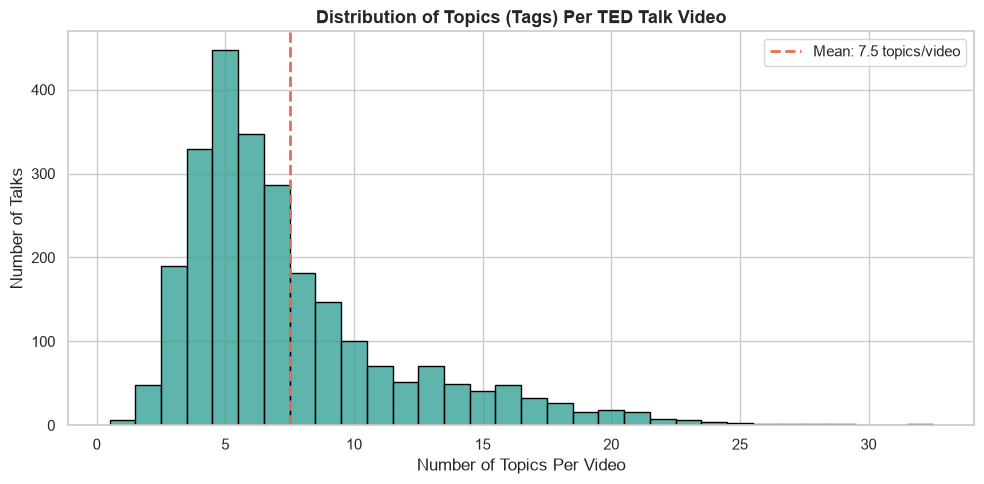

In [5]:
print("Topics Per Video Statistics:")
print(clean_df['tag_count'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(clean_df['tag_count'], bins=25, discrete=True, color='#2a9d8f', edgecolor='black')
plt.axvline(clean_df['tag_count'].mean(), color='#e76f51', linestyle='--', linewidth=2, label=f"Mean: {clean_df['tag_count'].mean():.1f} topics/video")
plt.title("Distribution of Topics (Tags) Per TED Talk Video", fontsize=13, weight='bold')
plt.xlabel("Number of Topics Per Video")
plt.ylabel("Number of Talks")
plt.legend()
plt.tight_layout()
plt.show()

### Step 6: Exploratory Data Analysis — Talk Durations (Validity Check)

Average Talk Duration: 13.8 minutes
Median Talk Duration: 14.1 minutes
Duration Range: 2.2 to 87.6 minutes


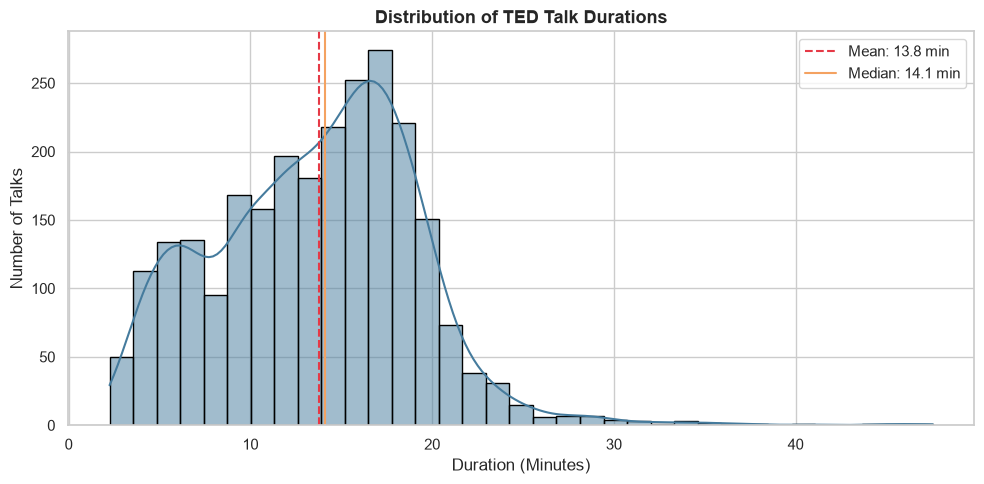

In [6]:
print(f"Average Talk Duration: {clean_df['duration_minutes'].mean():.1f} minutes")
print(f"Median Talk Duration: {clean_df['duration_minutes'].median():.1f} minutes")
print(f"Duration Range: {clean_df['duration_minutes'].min():.1f} to {clean_df['duration_minutes'].max():.1f} minutes")

plt.figure(figsize=(10, 5))
sns.histplot(clean_df['duration_minutes'][clean_df['duration_minutes'] < 50], bins=35, kde=True, color='#457b9d', edgecolor='black')
plt.axvline(clean_df['duration_minutes'].mean(), color='#e63946', linestyle='--', label=f"Mean: {clean_df['duration_minutes'].mean():.1f} min")
plt.axvline(clean_df['duration_minutes'].median(), color='#f4a261', linestyle='-', label=f"Median: {clean_df['duration_minutes'].median():.1f} min")
plt.title("Distribution of TED Talk Durations", fontsize=13, weight='bold')
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Talks")
plt.legend()
plt.tight_layout()
plt.show()

### Step 7: Exploratory Data Analysis — Top Categories & Most Viewed Talks

/tmp/ipykernel_200893/3443544668.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_tags.values, y=top_tags.index, palette="viridis")


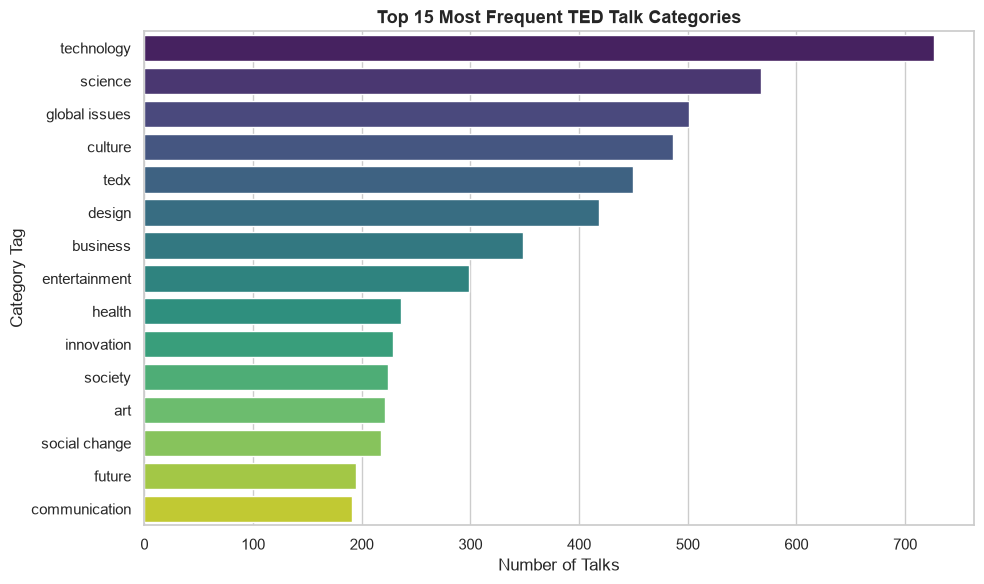

Top 5 Most Viewed Talks:


,title,main_speaker,views,duration_minutes
0,Do schools kill creativity?,Ken Robinson,47227110,19.40
1349,Your body language may shape who you are,Amy Cuddy,43155405,21.03
677,How great leaders inspire action,Simon Sinek,34309432,18.07
837,The power of vulnerability,Brené Brown,31168150,20.32
452,10 things you didn't know about orgasm,Mary Roach,22270883,16.72


In [7]:
# Top 15 Categories
all_tags = [t for tags in clean_df['tags_list'] for t in tags]
top_tags = pd.Series(all_tags).value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_tags.values, y=top_tags.index, palette="viridis")
plt.title("Top 15 Most Frequent TED Talk Categories", fontsize=13, weight='bold')
plt.xlabel("Number of Talks")
plt.ylabel("Category Tag")
plt.tight_layout()
plt.show()

# Top 5 Most Viewed Talks
print("Top 5 Most Viewed Talks:")
clean_df.sort_values(by='views', ascending=False)[['title', 'main_speaker', 'views', 'duration_minutes']].head(5)

### Step 8: Save Final Cleaned Dataset

In [8]:
os.makedirs("../data/processed", exist_ok=True)
output_file = "../data/processed/ted_talks_cleaned.csv"
clean_df.to_csv(output_file, index=False)
print(f"Cleaned dataset saved successfully to {output_file} ({os.path.getsize(output_file)/(1024*1024):.2f} MB)")

Cleaned dataset saved successfully to ../data/processed/ted_talks_cleaned.csv (68.48 MB)
